# Lending Decision Rules: Back-Testing and Champion/Challenger A/B Test

**Goal:** Turn the top default drivers from my Lending Club risk model (FICO, DTI, loan term) into simple decision-engine rules, back-test them out-of-time, compare two rule sets in an A/B test, and export metrics for a portfolio dashboard.

**Steps**
1. Load and quality-check the cleaned loan table
2. Write rules as a small decision engine with decline reason codes
3. Sweep cutoffs on the development period and pick a challenger policy
4. Back-test champion vs challenger on a later, out-of-time period
5. Run a randomized champion/challenger A/B test with significance testing
6. Monitor stability (monthly default rate, PSI)
7. Export tables for a Tableau / Power BI dashboard

## 0. Setup

**Data:** the cleaned `analytics.fct_loan_features` table (1.35M finished Lending Club loans) built by this repo's dbt models. Export it next to this notebook with:

```bash
docker compose exec -T warehouse psql -U loans -d warehouse -c "COPY (SELECT is_default, fico_range_low, dti, term_months, grade, int_rate, issue_date, loan_amnt FROM analytics.fct_loan_features) TO STDOUT WITH CSV HEADER" > notebooks/loans_for_rules.csv
```

The CSV is too large for GitHub and is git-ignored. Change `DATA_PATH` or `COLS` below only if your names differ.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

DATA_PATH = "loans_for_rules.csv"   # exported from analytics.fct_loan_features (see "Data" above)

COLS = {
    "target":    "is_default",       # 1 = defaulted / charged off, 0 = fully paid
    "fico":      "fico_range_low",
    "dti":       "dti",
    "term":      "term_months",      # 36 / 60
    "grade":     "grade",
    "int_rate":  "int_rate",
    "issue_d":   "issue_date",       # loan issue date
    "loan_amnt": "loan_amnt",
}
# Only used if your table has no 0/1 target column yet
STATUS_COL = "loan_status"
DEFAULT_STATUSES = ["Charged Off", "Default",
                    "Does not meet the credit policy. Status:Charged Off"]

TARGET_DEFAULT_RATE = 0.15   # risk appetite: max default rate among approved loans
DEV_SHARE = 0.70             # earliest 70% of loans by issue date = development period
SEED = 42

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

## 1. Load and standardize

In [5]:
path = Path(DATA_PATH)
if path.suffix == ".parquet":
    raw = pd.read_parquet(path)
else:
    header = pd.read_csv(path, nrows=0).columns
    wanted = [c for c in list(COLS.values()) + [STATUS_COL] if c in header]
    raw = pd.read_csv(path, usecols=wanted, low_memory=False)   # only the columns we need: much faster

needed = {k: v for k, v in COLS.items() if k != "target"}
missing = [v for v in needed.values() if v not in raw.columns]
if missing:
    raise KeyError(f"Update COLS: these columns are not in your table: {missing}")

if COLS["target"] not in raw.columns:
    # Raw Lending Club file: keep only finished loans (paid off or defaulted), drop "Current", "Late", etc.
    finished = DEFAULT_STATUSES + ["Fully Paid", "Does not meet the credit policy. Status:Fully Paid"]
    raw = raw[raw[STATUS_COL].isin(finished)].copy()
    raw[COLS["target"]] = raw[STATUS_COL].isin(DEFAULT_STATUSES).astype(int)
    print(f"Built target from {STATUS_COL}: kept {len(raw):,} finished loans")

def to_number(s):
    return pd.to_numeric(s.astype(str).str.replace("%", "", regex=False).str.strip(), errors="coerce")

def to_date(s):
    d = pd.to_datetime(s, format="%b-%Y", errors="coerce")
    if d.isna().mean() > 0.5:                      # not "Dec-2015" style: let pandas infer
        d = pd.to_datetime(s, errors="coerce")
    return d

df = pd.DataFrame({
    "default":   raw[COLS["target"]].astype(int),
    "fico":      to_number(raw[COLS["fico"]]),
    "dti":       to_number(raw[COLS["dti"]]),
    "term":      raw[COLS["term"]].astype(str).str.extract(r"(\d+)")[0].astype(float),
    "grade":     raw[COLS["grade"]].astype(str).str.strip(),
    "int_rate":  to_number(raw[COLS["int_rate"]]),
    "issue_d":   to_date(raw[COLS["issue_d"]]),
    "loan_amnt": to_number(raw[COLS["loan_amnt"]]),
})
print(f"{len(df):,} loans loaded")
df.head()

1,348,099 loans loaded


,default,fico,dti,term,grade,int_rate,issue_d,loan_amnt
0,0,670,28.1700,36.0000,D,18.9400,2018-09-01,10000
1,1,705,16.9100,60.0000,D,20.8900,2018-09-01,10000
2,0,710,29.2000,60.0000,D,17.9700,2018-09-01,22000
3,0,670,28.1900,36.0000,D,20.8900,2018-09-01,6000
4,0,725,14.0900,60.0000,A,7.8400,2018-09-01,18000


## 2. Data quality checks
Rules are only as good as their inputs, so check nulls and impossible values before writing any rule.

In [7]:
checks = pd.DataFrame({
    "nulls": df.isna().sum(),
    "null_pct": df.isna().mean(),
})
print(checks, "\n")

issues = {
    "FICO outside 300-850":        (~df["fico"].between(300, 850)) & df["fico"].notna(),
    "DTI negative or above 100":   (~df["dti"].between(0, 100)) & df["dti"].notna(),
    "Term not 36 or 60 months":    (~df["term"].isin([36, 60])) & df["term"].notna(),
    "Target not 0/1":              ~df["default"].isin([0, 1]),
}
for name, mask in issues.items():
    print(f"{name:<28} {mask.sum():>10,} rows")

key = ["default", "fico", "dti", "term", "issue_d"]
bad = df[key].isna().any(axis=1) | issues["FICO outside 300-850"] | issues["DTI negative or above 100"]
df = df[~bad].copy()
print(f"\nKept {len(df):,} loans after removing {bad.sum():,} rows that failed checks")

           nulls  null_pct
default        0    0.0000
fico           0    0.0000
dti          374    0.0003
term           0    0.0000
grade          0    0.0000
int_rate       0    0.0000
issue_d        0    0.0000
loan_amnt      0    0.0000 

FICO outside 300-850                  0 rows
DTI negative or above 100           535 rows
Term not 36 or 60 months              0 rows
Target not 0/1                        0 rows

Kept 1,347,190 loans after removing 909 rows that failed checks


## 3. Portfolio baseline

In [9]:
print(f"Overall default rate: {df['default'].mean():.2%}\n")
baseline = (df.groupby("grade")
              .agg(loans=("default", "size"), default_rate=("default", "mean"),
                   avg_fico=("fico", "mean"), avg_dti=("dti", "mean"))
              .sort_index())
baseline

Overall default rate: 19.98%



,loans,default_rate,avg_fico,avg_dti
grade,,,,
A,235108,0.0604,727.5241,15.5629
B,392886,0.1340,697.1330,17.3006
C,382030,0.2244,687.9736,18.8082
D,201475,0.3038,683.2549,20.0255
E,94106,0.3844,681.9573,20.6358
F,32279,0.4515,679.7949,20.8327
G,9306,0.4967,678.1926,21.0928


## 4. Decision engine
Each rule is a named decline condition. A loan is declined by the **first** rule it hits, which gives every decline a reason code, the way a production decision engine does.

In [11]:
def apply_rules(d, rules):
    """Return (approved mask, decline reason per loan)."""
    declined = pd.Series(False, index=d.index)
    reason = pd.Series("Approved", index=d.index)
    for r in rules:
        hit = r["decline_if"](d) & ~declined
        reason[hit] = r["name"]
        declined |= hit
    return ~declined, reason

def evaluate(d, approved):
    goods = d["default"] == 0
    n_app = approved.sum()
    return {
        "approval_rate":         n_app / len(d),
        "default_rate_approved": d.loc[approved, "default"].mean() if n_app else np.nan,
        "defaults_avoided_pct":  1 - d.loc[approved, "default"].sum() / d["default"].sum(),
        "good_loans_lost_pct":   (~approved & goods).sum() / goods.sum(),
        "approved_loans":        int(n_app),
    }

def policy(fico_min, dti_max=np.inf, long_term_dti_max=np.inf):
    return [
        {"name": f"FICO < {fico_min}",            "decline_if": lambda d: d["fico"] < fico_min},
        {"name": f"DTI > {dti_max:g}",            "decline_if": lambda d: d["dti"] > dti_max},
        {"name": f"60-mo term & DTI > {long_term_dti_max:g}",
         "decline_if": lambda d: (d["term"] == 60) & (d["dti"] > long_term_dti_max)},
    ]

# Champion = a simple single-rule baseline. Lending Club only funded FICO >= 660,
# so a 660 floor would approve every loan; 680 makes it a real policy.
CHAMPION = {"fico_min": 680}

## 5. Mature loans only, then split by time
Back-testing means choosing rules on older loans and checking them on newer ones, just as a rule change would be judged after launch.

In [13]:
# Keep only loans whose full term had ended when the data was pulled. Newer loans that are
# already "finished" are mostly early defaults, which would inflate recent default rates.
DATA_AS_OF = pd.Timestamp("2019-03-31")   # last status update in the Lending Club file
loan_end = df["issue_d"] + pd.to_timedelta(df["term"] * 30.44, unit="D")
print(f"Dropped {(loan_end > DATA_AS_OF).sum():,} loans whose term had not ended by {DATA_AS_OF:%b %Y}")
df = df[loan_end <= DATA_AS_OF].copy()

df = df.sort_values("issue_d").reset_index(drop=True)
cut_date = df["issue_d"].quantile(DEV_SHARE)
dev  = df[df["issue_d"] <= cut_date].copy()
test = df[df["issue_d"] >  cut_date].copy()
print(f"Development: {dev['issue_d'].min():%b %Y} to {dev['issue_d'].max():%b %Y}  ({len(dev):,} loans)")
print(f"Out-of-time: {test['issue_d'].min():%b %Y} to {test['issue_d'].max():%b %Y}  ({len(test):,} loans)")

Dropped 568,196 loans whose term had not ended by Mar 2019
Development: Jun 2007 to Jul 2015  (557,869 loans)
Out-of-time: Aug 2015 to Mar 2016  (221,125 loans)


## 6. Cutoff sweep on the development period
Every combination of FICO floor and DTI cap, scored on approval rate vs default rate. The challenger is the policy that approves the most loans while keeping defaults within `TARGET_DEFAULT_RATE`.

In [15]:
rows = []
for fico_min in range(620, 761, 10):
    for dti_max in [25, 30, 35, 40, np.inf]:
        for lt_dti in [20, 25, 30, np.inf]:
            approved, _ = apply_rules(dev, policy(fico_min, dti_max, lt_dti))
            rows.append({"fico_min": fico_min, "dti_max": dti_max, "long_term_dti_max": lt_dti,
                         **evaluate(dev, approved)})
sweep = pd.DataFrame(rows)
sweep.to_csv(OUT / "rule_sweep.csv", index=False)

eligible = sweep[sweep["default_rate_approved"] <= TARGET_DEFAULT_RATE]
if eligible.empty:
    raise ValueError("No policy meets TARGET_DEFAULT_RATE. Raise it or widen the sweep.")
best = eligible.sort_values(["approval_rate", "default_rate_approved"], ascending=[False, True]).iloc[0]
CHALLENGER = {"fico_min": int(best["fico_min"]), "dti_max": float(best["dti_max"]),
              "long_term_dti_max": float(best["long_term_dti_max"])}
print("Challenger policy:", CHALLENGER)
best

Challenger policy: {'fico_min': 620, 'dti_max': 35.0, 'long_term_dti_max': 30.0}


fico_min                    620.0000
dti_max                      35.0000
long_term_dti_max            30.0000
approval_rate                 0.9802
default_rate_approved         0.1495
defaults_avoided_pct          0.0329
good_loans_lost_pct           0.0174
approved_loans          546,836.0000
Name: 10, dtype: float64

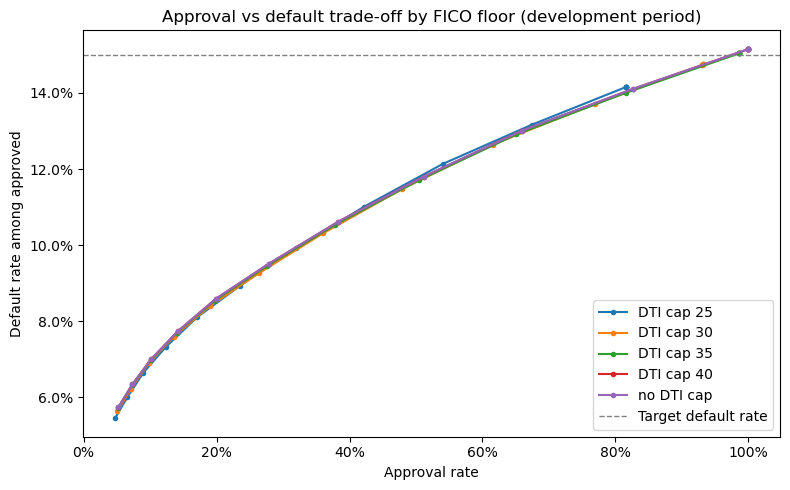

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
for dti_max, g in sweep[sweep["long_term_dti_max"] == np.inf].groupby("dti_max"):
    label = "no DTI cap" if np.isinf(dti_max) else f"DTI cap {dti_max:g}"
    ax.plot(g["approval_rate"], g["default_rate_approved"], marker="o", ms=3, label=label)
ax.axhline(TARGET_DEFAULT_RATE, ls="--", c="gray", lw=1, label="Target default rate")
ax.set_xlabel("Approval rate"); ax.set_ylabel("Default rate among approved")
ax.set_title("Approval vs default trade-off by FICO floor (development period)")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.legend(); plt.tight_layout(); plt.savefig(OUT / "tradeoff.png", dpi=150); plt.show()

## 7. Out-of-time back-test: champion vs challenger

In [18]:
results = {}
for name, cfg in {"Champion": CHAMPION, "Challenger": CHALLENGER}.items():
    for period, d in {"Development": dev, "Out-of-time": test}.items():
        approved, _ = apply_rules(d, policy(**cfg))
        results[(name, period)] = evaluate(d, approved)
backtest = pd.DataFrame(results).T
backtest.to_csv(OUT / "backtest.csv")
backtest

approval_rate  default_rate_approved  \
Champion   Development         0.6595                 0.1301   
           Out-of-time         0.6400                 0.1247   
Challenger Development         0.9802                 0.1495   
           Out-of-time         0.9598                 0.1492   

                        defaults_avoided_pct  good_loans_lost_pct  \
Champion   Development                0.4340               0.3238   
           Out-of-time                0.4780               0.3387   
Challenger Development                0.0329               0.0174   
           Out-of-time                0.0631               0.0361   

                        approved_loans  
Champion   Development    367,913.0000  
           Out-of-time    141,511.0000  
Challenger Development    546,836.0000  
           Out-of-time    212,233.0000

In [19]:
# Why loans get declined under the challenger (reason codes)
_, reasons = apply_rules(test, policy(**CHALLENGER))
reason_tbl = (test.assign(reason=reasons)
                  .groupby("reason")
                  .agg(loans=("default", "size"), default_rate=("default", "mean")))
reason_tbl["share"] = reason_tbl["loans"] / len(test)
reason_tbl.sort_values("loans", ascending=False)

,loans,default_rate,share
reason,,,
Approved,212233,0.1492,0.9598
DTI > 35,8892,0.2400,0.0402


## 8. Champion/challenger A/B test
Randomly assign out-of-time applicants 50/50. Group A gets the champion rules, group B the challenger. A two-proportion z-test checks whether the differences are real or noise.

**Caveat (good to raise in an interview):** Lending Club data only contains loans that were funded, so outcomes for applicants who were originally rejected are unknown. This test compares policies within the funded population; a live test would also need reject inference.

In [21]:
rng = np.random.default_rng(SEED)
test["group"] = np.where(rng.random(len(test)) < 0.5, "A_champion", "B_challenger")
A = test[test["group"] == "A_champion"]
B = test[test["group"] == "B_challenger"]
appA, _ = apply_rules(A, policy(**CHAMPION))
appB, _ = apply_rules(B, policy(**CHALLENGER))

def two_prop_ztest(x1, n1, x2, n2):
    p1, p2 = x1 / n1, x2 / n2
    pooled = (x1 + x2) / (n1 + n2)
    se = np.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
    z = (p2 - p1) / se
    p_value = 2 * (1 - norm.cdf(abs(z)))
    se_diff = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    ci = (p2 - p1 - 1.96 * se_diff, p2 - p1 + 1.96 * se_diff)
    return p1, p2, z, p_value, ci

ab_rows = []
for metric, (x1, n1, x2, n2) in {
    "Approval rate": (appA.sum(), len(A), appB.sum(), len(B)),
    "Default rate among approved": (A.loc[appA, "default"].sum(), appA.sum(),
                                    B.loc[appB, "default"].sum(), appB.sum()),
}.items():
    p1, p2, z, p, ci = two_prop_ztest(x1, n1, x2, n2)
    ab_rows.append({"metric": metric, "A_champion": p1, "B_challenger": p2,
                    "difference": p2 - p1, "ci_low": ci[0], "ci_high": ci[1],
                    "z": z, "p_value": p, "significant_at_5pct": p < 0.05})
ab = pd.DataFrame(ab_rows).set_index("metric")
ab.to_csv(OUT / "ab_test_results.csv")
ab

,A_champion,B_challenger,difference,ci_low,ci_high,z,p_value,significant_at_5pct
metric,,,,,,,,
Approval rate,0.6389,0.9588,0.3199,0.3168,0.3230,187.7116,0.0000,True
Default rate among approved,0.1255,0.1476,0.0221,0.0189,0.0253,13.1610,0.0000,True


## 9. Monitoring: is the challenger stable over time?
Monthly default rate of approved loans, plus PSI on FICO between development and out-of-time applicants (PSI < 0.10 stable, 0.10–0.25 watch, > 0.25 shifted).

fico       0.0026
dti        0.0259
int_rate   0.2443
Name: PSI, dtype: float64 



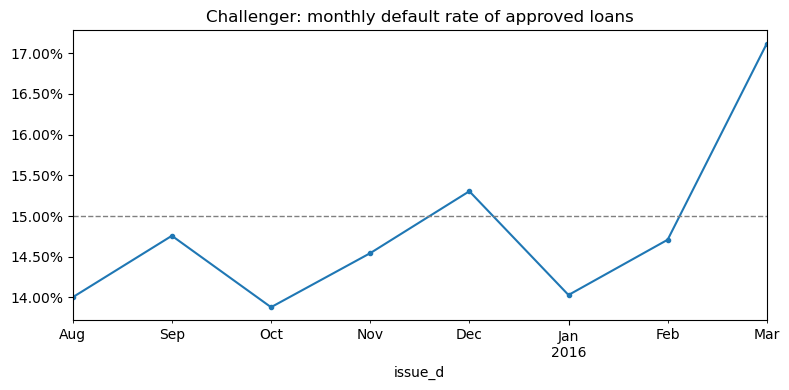

In [23]:
def psi(expected, actual, bins=10):
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    e = np.histogram(expected, edges)[0] / len(expected)
    a = np.histogram(np.clip(actual, edges[0], edges[-1]), edges)[0] / len(actual)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))

psi_tbl = pd.Series({c: psi(dev[c], test[c]) for c in ["fico", "dti", "int_rate"]}, name="PSI")
print(psi_tbl, "\n")

appT, _ = apply_rules(test, policy(**CHALLENGER))
monthly = (test[appT].groupby(test["issue_d"].dt.to_period("M"))["default"]
                     .agg(["size", "mean"]).rename(columns={"size": "approved", "mean": "default_rate"}))
ax = monthly["default_rate"].plot(figsize=(8, 4), marker="o", ms=3,
                                  title="Challenger: monthly default rate of approved loans")
ax.axhline(TARGET_DEFAULT_RATE, ls="--", c="gray", lw=1)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.tight_layout(); plt.savefig(OUT / "monitoring.png", dpi=150); plt.show()

## 10. Export for the dashboard
One tidy table by month, grade, and term, with both policies' decisions. Load `dashboard_monthly.csv` into Tableau or Power BI to chart approval rate, default rate, and volume.

In [25]:
full = df.copy()
full["approved_champion"], _ = apply_rules(full, policy(**CHAMPION))
full["approved_challenger"], _ = apply_rules(full, policy(**CHALLENGER))
full["period"] = np.where(full["issue_d"] <= cut_date, "Development", "Out-of-time")
full["month"] = full["issue_d"].dt.to_period("M").dt.to_timestamp()

def agg(g):
    out = {"loans": len(g), "loan_amount": g["loan_amnt"].sum(), "default_rate_all": g["default"].mean()}
    for p in ["champion", "challenger"]:
        app = g[f"approved_{p}"]
        out[f"approval_rate_{p}"] = app.mean()
        out[f"default_rate_{p}"] = g.loc[app, "default"].mean() if app.any() else np.nan
    return pd.Series(out)

dash = full.groupby(["month", "period", "grade", "term"]).apply(agg, include_groups=False).reset_index()
dash.to_csv(OUT / "dashboard_monthly.csv", index=False)
print(f"Saved {len(dash):,} rows to outputs/dashboard_monthly.csv")

Saved 1,050 rows to outputs/dashboard_monthly.csv


## 11. Results summary

In [27]:
oot = backtest.xs("Out-of-time", level=1)
c, h = oot.loc["Champion"], oot.loc["Challenger"]
print(f"Loans analyzed:            {len(df):,}")
print(f"Development / out-of-time: {len(dev):,} / {len(test):,}")
print(f"Policies back-tested:      {len(sweep):,}")
print(f"Champion:   {CHAMPION}")
print(f"Challenger: {CHALLENGER}")
print(f"Out-of-time approval rate: {c['approval_rate']:.1%} -> {h['approval_rate']:.1%}")
print(f"Out-of-time default rate:  {c['default_rate_approved']:.2%} -> {h['default_rate_approved']:.2%}")
print(f"Defaults avoided:          {c['defaults_avoided_pct']:.1%} -> {h['defaults_avoided_pct']:.1%}")
for m, r in ab.iterrows():
    print(f"A/B {m}: {r['A_champion']:.2%} vs {r['B_challenger']:.2%}, p = {r['p_value']:.4f}")
print("PSI:", psi_tbl.round(3).to_dict())

Loans analyzed:            778,994
Development / out-of-time: 557,869 / 221,125
Policies back-tested:      300
Champion:   {'fico_min': 680}
Challenger: {'fico_min': 620, 'dti_max': 35.0, 'long_term_dti_max': 30.0}
Out-of-time approval rate: 64.0% -> 96.0%
Out-of-time default rate:  12.47% -> 14.92%
Defaults avoided:          47.8% -> 6.3%
A/B Approval rate: 63.89% vs 95.88%, p = 0.0000
A/B Default rate among approved: 12.55% vs 14.76%, p = 0.0000
PSI: {'fico': 0.003, 'dti': 0.026, 'int_rate': 0.244}
